In [55]:
import numpy as np
import pandas as pd
from src.data_loader import *
from torchvision import transforms
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Carregamento dos dados:

In [51]:
root = "pa3_dados"

In [52]:
dim_classes = pd.read_csv(f"{root}/classes.csv")

In [60]:
y_train = get_labels(root, labels_qtt=5)
y_val   = get_labels(root, name_file="val")
y_test  = get_labels(root, name_file="test_public")


y_train_map = {
    k: v["label"]
    for k, v in y_train.set_index("image_id").to_dict(orient="index").items()
}

y_val_map = {
    k: v["label"]
    for k, v in y_val.set_index("image_id").to_dict(orient="index").items()
}

y_test_map = {
    k: v["label"]
    for k, v in y_test.set_index("image_id").to_dict(orient="index").items()
}

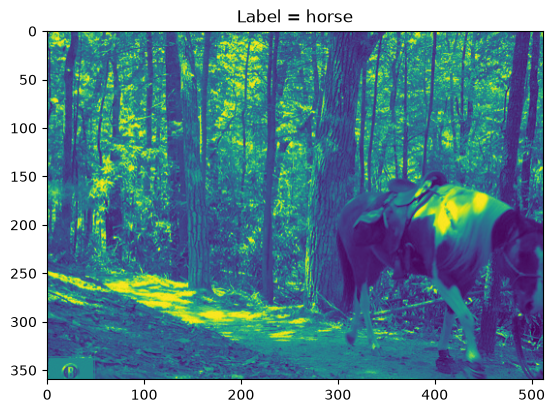

In [62]:
transform_unsupervised = transforms.Compose([
    transforms.Resize((360, 512)), # Resize para um dimensionamento padrao
    transforms.ToTensor(),
    transforms.Grayscale()
])

# Instancia os Datasets de treino, validacao e teste
train_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='train', 
    transform=transform_unsupervised
)
val_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='val', 
    transform=transform_unsupervised
)
test_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='test_public', 
    transform=transform_unsupervised
)

# Cria os DataLoaders
loader_params = {
    "batch_size": 16, 
    "shuffle": True,  # Para treino, embaralhamos os dados
    "num_workers": 2, 
}
train_loader = DataLoader(train_dataset, **loader_params)
val_loader   = DataLoader(val_dataset, **loader_params)
test_loader  = DataLoader(test_dataset, **loader_params)


# Testando um batch
find = False
for images, image_ids in train_loader:
    for image, image_id in zip(images, image_ids):
        label = y_train_map.get(image_id, None)
        if label:
            image = image.numpy().transpose((1, 2, 0))
            image = np.clip(image, 0, 1)
            plt.imshow(image)
            plt.title(f"Label = {label}")
            find = True
            break
        
    if find:
        break